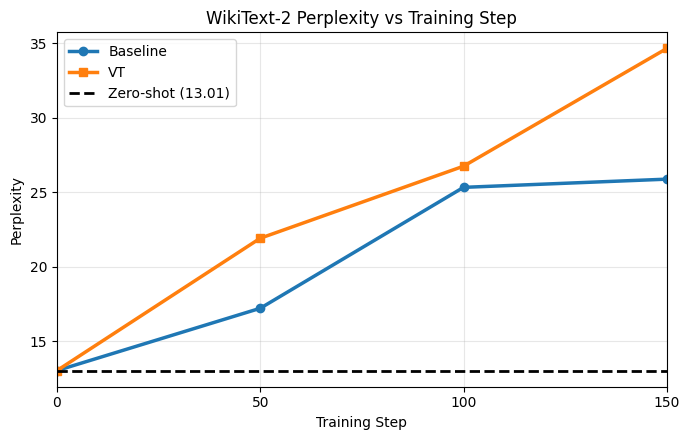

In [6]:
import pandas as pd
import matplotlib.pyplot as plt

# Load CSV
df = pd.read_csv("vt_wikitext2_perplexity_by_step.csv")

df["checkpoint_step_numeric"] = pd.to_numeric(
    df["checkpoint_step_numeric"], errors="coerce"
)

# Zero-shot perplexity
zeroshot_ppl = df.loc[
    df["model_type"] == "zero_shot",
    "perplexity_wikitext2"
].iloc[0]

# Keep only checkpoints up to 150
df = df[df["checkpoint_step_numeric"] <= 150]

# Extract baseline and VT curves
baseline = (
    df[df["model_type"] == "baseline"]
    .sort_values("checkpoint_step_numeric")
    [["checkpoint_step_numeric", "perplexity_wikitext2"]]
)

vt = (
    df[df["model_type"] == "vt"]
    .sort_values("checkpoint_step_numeric")
    [["checkpoint_step_numeric", "perplexity_wikitext2"]]
)

# Add zero-shot starting point at step 0
baseline = pd.concat(
    [
        pd.DataFrame({
            "checkpoint_step_numeric": [0],
            "perplexity_wikitext2": [zeroshot_ppl]
        }),
        baseline
    ],
    ignore_index=True
)

vt = pd.concat(
    [
        pd.DataFrame({
            "checkpoint_step_numeric": [0],
            "perplexity_wikitext2": [zeroshot_ppl]
        }),
        vt
    ],
    ignore_index=True
)

# Plot
plt.figure(figsize=(7, 4.5))

# Baseline curve
plt.plot(
    baseline["checkpoint_step_numeric"],
    baseline["perplexity_wikitext2"],
    marker="o",
    linewidth=2.5,
    label="Baseline",
)

# VT curve
plt.plot(
    vt["checkpoint_step_numeric"],
    vt["perplexity_wikitext2"],
    marker="s",
    linewidth=2.5,
    label="VT",
)

# Zero-shot constant line
plt.axhline(
    y=zeroshot_ppl,
    color="black",
    linestyle="--",
    linewidth=2,
    label=f"Zero-shot ({zeroshot_ppl:.2f})",
)

plt.xlim(0, 150)
plt.xticks([0, 50, 100, 150])

plt.xlabel("Training Step")
plt.ylabel("Perplexity")
plt.title("WikiText-2 Perplexity vs Training Step")
plt.grid(alpha=0.3)
plt.legend()

plt.tight_layout()
plt.show()

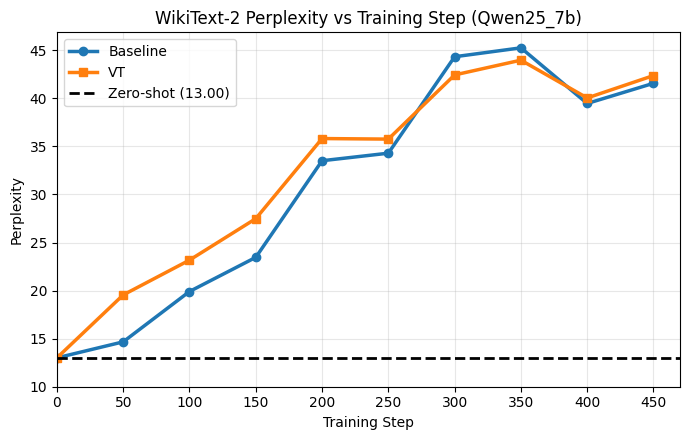

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import json

df = pd.DataFrame()
MODEL = "qwen25_7b"

for model in ['zeroshot', 'baseline', 'vt']:
    if model == 'zeroshot':
        folder = f'{MODEL}/results_{model}'
        with open(f'{folder}/metrics.json', "r") as f:
            data = json.load(f)
        zeroshot_ppl = data['perplexity_wikitext2']
    else:
        for step in range(50, 500, 50):
            folder = f'{MODEL}/results_{model}_step_{step}'
            with open(f'{folder}/metrics.json', "r") as f:
                data = json.load(f)
            df = pd.concat([df, pd.DataFrame([data])], ignore_index=True)

df = df[['model_type', 'checkpoint_step', 'perplexity_wikitext2']]

# Extract baseline and VT curves
baseline = (
    df[df["model_type"] == "baseline"]
    .sort_values("checkpoint_step")
    [["checkpoint_step", "perplexity_wikitext2"]]
)

vt = (
    df[df["model_type"] == "vt"]
    .sort_values("checkpoint_step")
    [["checkpoint_step", "perplexity_wikitext2"]]
)

# Add zero-shot starting point at step 0
baseline = pd.concat(
    [
        pd.DataFrame({
            "checkpoint_step": [0],
            "perplexity_wikitext2": [zeroshot_ppl]
        }),
        baseline
    ],
    ignore_index=True
)

vt = pd.concat(
    [
        pd.DataFrame({
            "checkpoint_step": [0],
            "perplexity_wikitext2": [zeroshot_ppl]
        }),
        vt
    ],
    ignore_index=True
)

# Plot
plt.figure(figsize=(7, 4.5))

# Baseline curve
plt.plot(
    baseline["checkpoint_step"],
    baseline["perplexity_wikitext2"],
    marker="o",
    linewidth=2.5,
    label="Baseline",
)

# VT curve
plt.plot(
    vt["checkpoint_step"],
    vt["perplexity_wikitext2"],
    marker="s",
    linewidth=2.5,
    label="VT",
)

# Zero-shot constant line
plt.axhline(
    y=zeroshot_ppl,
    color="black",
    linestyle="--",
    linewidth=2,
    label=f"Zero-shot ({zeroshot_ppl:.2f})",
)

plt.xlim(0, 470)
plt.xticks([i for i in range(0, 500, 50)])
plt.ylim(bottom=10)

plt.xlabel("Training Step")
plt.ylabel("Perplexity")
plt.title(f"WikiText-2 Perplexity vs Training Step ({MODEL.capitalize()})")
plt.grid(alpha=0.3)
plt.legend()

plt.tight_layout()
plt.savefig(f'./figures/{MODEL}_perplexity.png', dpi=600, bbox_inches='tight')
plt.show()

## Combine figures

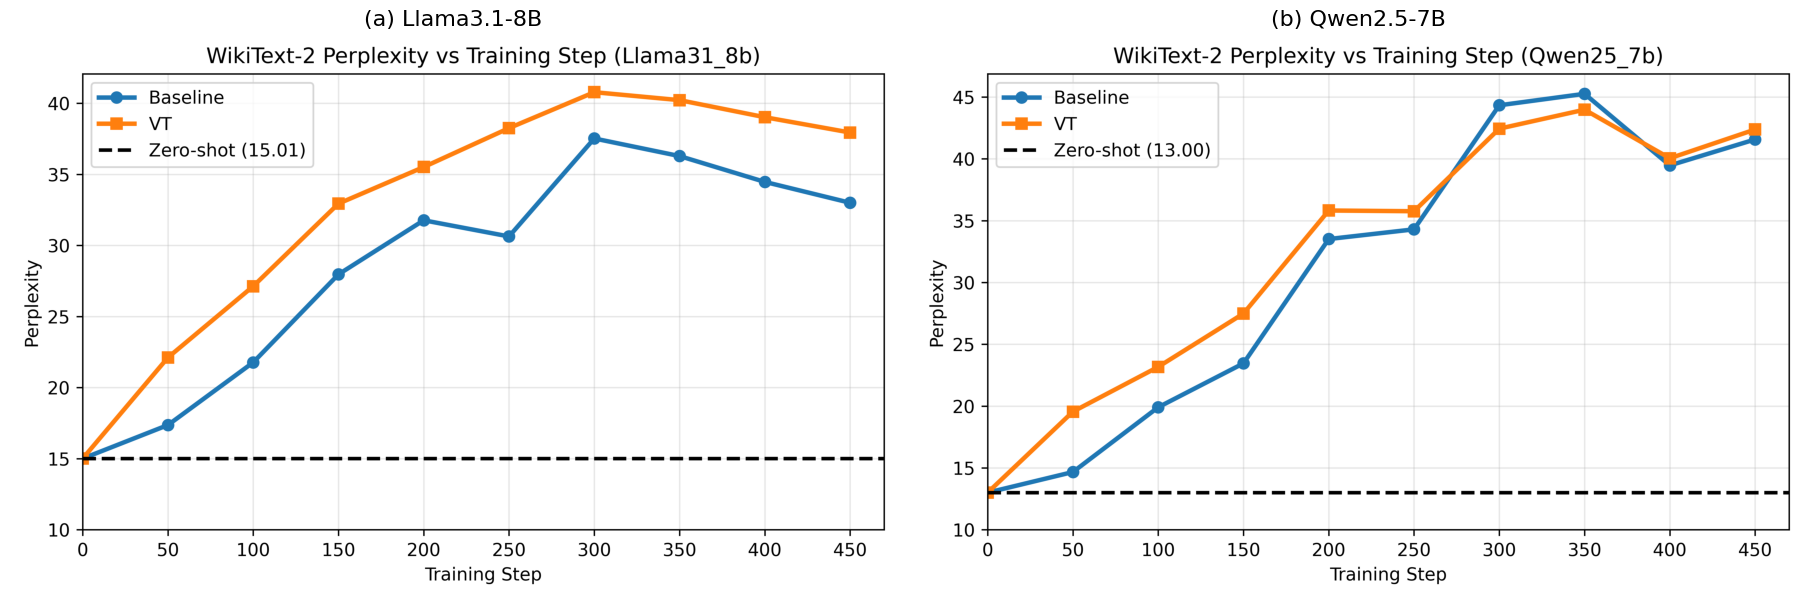

In [4]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

FIG_DIR = './figures'
img1 = mpimg.imread(f"{FIG_DIR}/llama31_8b_perplexity.png")
img2 = mpimg.imread(f"{FIG_DIR}/qwen25_7b_perplexity.png")

fig, axes = plt.subplots(
    1, 2,
    figsize=(18, 8),
    constrained_layout=True
)

axes[0].imshow(img1)
axes[0].axis("off")
axes[0].set_title("(a) Llama3.1-8B", fontsize=16)

axes[1].imshow(img2)
axes[1].axis("off")
axes[1].set_title("(b) Qwen2.5-7B", fontsize=16)

plt.savefig(f"./figures/perplexity.png", dpi=600, bbox_inches="tight")
plt.show()
